# Simulated packs vs real Arena packs

How close are the packs from `packs.js` to real MTG Arena Premier Draft packs?

**Real packs:** 17Lands P1P1 packs, which are whole, unopened packs. They come only from the half of the drafts that
`tools/fit_rates.py` never fit on (draft ids ending in an odd hex digit), so every comparison here is out-of-sample.

**Simulated packs:** opened by `packs.js` (through `tools/gen_packs.mjs`) from the collation in `data/{SET}.json`.

**The main test, likelihood:** every pack gets a log-probability under the generator:
`log P(pack) ≈ log P(how many cards it has from each sheet) + Σ log P(card | its sheet)`.
Both terms are estimated from 200,000 simulated packs. Held-out simulated packs and real packs are then scored the same way.
If the generator is right, the two score distributions are the same, and the KS test can't tell them apart.

**The other checks:** per-sheet counts, per-card frequencies, duplicates and colour balance. These cover what the score can't see.

The notebook needs the 17Lands parquet files from ../mtg-data and `node`. A full run takes about 5 minutes.

In [1]:
import json, sys
from collections import Counter
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import stats

SITE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(SITE / "tools"))
from verify_packs import real_packs, sim_packs, Model, same_colour_ratio, colours_present
from collation import SETS

N_REAL, N_SIM = 20_000, 200_000
CODES = [s["code"] for s in json.loads((SITE / "data" / "sets.json").read_text())]

# Two series throughout: real packs (blue) and simulated packs (orange). Validated palette, light mode.
REAL, SIM, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 9, "legend.frameon": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
})

In [2]:
def analyze(code, rng):
    data = json.loads((SITE / "data" / f"{code}.json").read_text())
    col, cards = data["collation"], {int(k): v for k, v in data["cards"].items()}
    colors = {k: v["colors"] for k, v in cards.items()}
    sheet_of = {}
    for s, ids in col["sheets"].items():
        for c in ids:
            sheet_of.setdefault(c, s)
    label = lambda c: sheet_of.get(c, "?")

    real, _ = real_packs(code, {v["name"]: k for k, v in cards.items()}, N_REAL, rng)
    sim = sim_packs(code, N_SIM + len(real), int(rng.integers(1 << 30)))
    fit, held = sim[:N_SIM], sim[N_SIM:]
    m = Model(fit, label)
    rs, hs = np.array([m.score(p) for p in real]), np.array([m.score(p) for p in held])

    # per-sheet counts per pack
    sheets = list(col["sheets"])
    cnt = lambda ps: np.array([[sum(label(c) == s for c in p) for s in sheets] for p in ps], float)
    cr, ch = cnt(real), cnt(held)
    z = (cr.mean(0) - ch.mean(0)) / np.sqrt(cr.var(0) / len(cr) + ch.var(0) / len(ch) + 1e-12)

    # per-card frequency (copies per pack), real vs the 200k simulated packs
    rc, fc = Counter(c for p in real for c in p), Counter(c for p in fit for c in p)
    ids = sorted(sheet_of)
    card = pl.DataFrame({"set": code, "card": [cards[c]["name"] for c in ids], "sheet": [sheet_of[c] for c in ids],
                         "real": [rc[c] / len(real) for c in ids], "sim": [fc[c] / len(fit) for c in ids]})
    chi = []
    for s in sheets:
        own = [c for c in col["sheets"][s] if sheet_of[c] == s]
        a, b = np.array([rc[c] for c in own], float), np.array([fc[c] for c in own], float)
        keep = (a + b) > 0
        if keep.sum() >= 2 and a.sum() >= 30:
            chi.append((s, stats.chi2_contingency(np.stack([a[keep], b[keep]]))[1]))

    bal = col["sheets"][col["balance"]["sheet"]]
    inb = set(bal)
    five = lambda ps: np.mean([colours_present(p, lambda c: c in inb, colors) for p in ps])
    dup = lambda ps: np.mean([len(set(p)) < len(p) for p in ps])
    fin = lambda a: a[np.isfinite(a)]
    ks = {name: stats.ks_2samp(fin(a), fin(b)) for name, a, b in
          (("log P(pack)", rs.sum(1), hs.sum(1)), ("sheet mix", rs[:, 0], hs[:, 0]), ("cards", rs[:, 1], hs[:, 1]))}
    return dict(code=code, n_real=len(real), n_held=len(held), ks=ks, score_real=rs.sum(1), score_sim=hs.sum(1),
                impossible=float(np.mean(~np.isfinite(rs.sum(1)))),
                sheets=pl.DataFrame({"set": code, "sheet": sheets, "real": cr.mean(0), "sim": ch.mean(0), "z": z}),
                card=card, chi=chi, dup=(dup(real), dup(held)), five=(five(real), five(held)),
                pairs=(same_colour_ratio(real, bal, colors), same_colour_ratio(held, bal, colors)))

rng = np.random.default_rng(0)
R = {}
for code in CODES:
    R[code] = analyze(code, rng)
    print(code, "done", end="; ")

BLB done; 

DFT done; 

DSK done; 

ECL done; 

EOE done; 

...

SOS done; 

TDM done; 

TLA done; 

TMT done; 

WOE done; 

## 1. Summary

A row per set:
- **KS D:** the largest gap between the real and simulated score distributions. The *noise* column is the D you'd expect
  from sampling alone (the 5% critical value for these sample sizes). Below noise means the test can't tell real packs
  from simulated ones.
- **Impossible:** the share of real packs that the generator never produced in 200,000 tries.
- **Worst |z|:** the largest standardised gap in mean cards per pack, over the set's sheets.
- **Min chi p:** the lowest per-card chi-square p-value, over the set's sheets.

In [3]:
crit = lambda n, m: 1.358 * np.sqrt((n + m) / (n * m))  # KS 5% critical value
summary = pl.DataFrame([{
    "set": r["code"],
    "KS D log P": round(r["ks"]["log P(pack)"].statistic, 4),
    "KS D sheet mix": round(r["ks"]["sheet mix"].statistic, 4),
    "KS D cards": round(r["ks"]["cards"].statistic, 4),
    "noise (5%)": round(crit(r["n_real"], r["n_held"]), 4),
    "impossible": f"{r['impossible']:.2%}",
    "worst |z|": round(float(r["sheets"]["z"].abs().max()), 1),
    "min chi p": float(f"{min(p for _, p in r['chi']):.2g}"),
    "dup real": round(r["dup"][0], 4), "dup sim": round(r["dup"][1], 4),
    "5 colours real": round(r["five"][0], 3), "5 colours sim": round(r["five"][1], 3),
} for r in R.values()])
pl.Config.set_tbl_rows(30); pl.Config.set_tbl_cols(20)
summary

set,KS D log P,KS D sheet mix,KS D cards,noise (5%),impossible,worst |z|,min chi p,dup real,dup sim,5 colours real,5 colours sim
str,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64
"""BLB""",0.0114,0.007,0.007,0.0136,"""0.00%""",2.1,0.17,0.0696,0.0676,1.0,1.0
"""DFT""",0.0097,0.0067,0.0099,0.0136,"""0.00%""",2.5,0.036,0.0025,0.0,1.0,1.0
"""DSK""",0.0059,0.0051,0.0072,0.0136,"""0.01%""",1.2,0.17,0.0654,0.0629,1.0,1.0
"""ECL""",0.0132,0.0081,0.0073,0.0136,"""0.00%""",1.1,0.26,0.002,0.0,1.0,1.0
"""EOE""",0.0083,0.0062,0.0066,0.0136,"""0.00%""",1.4,0.22,0.0,0.0,1.0,1.0
"""FDN""",0.0087,0.0117,0.0111,0.0136,"""0.00%""",2.1,0.056,0.0679,0.0637,1.0,1.0
"""FIN""",0.0084,0.0103,0.0121,0.0136,"""0.00%""",1.0,0.27,0.0,0.0,1.0,1.0
"""LCI""",0.0084,0.0037,0.0074,0.0136,"""0.00%""",0.5,0.067,0.0,0.0,1.0,1.0
"""MKM""",0.0124,0.0053,0.007,0.0136,"""0.00%""",1.9,0.12,0.0649,0.0649,1.0,1.0


## 2. Likelihood test: KS distance per set

These are the KS distances between the real and simulated distributions of each score.
- **log P:** the total score.
- **Sheet mix:** only the "how many cards from each sheet" part.
- **Cards:** only the "which cards within each sheet" part.

The dashed line is the sampling-noise level.

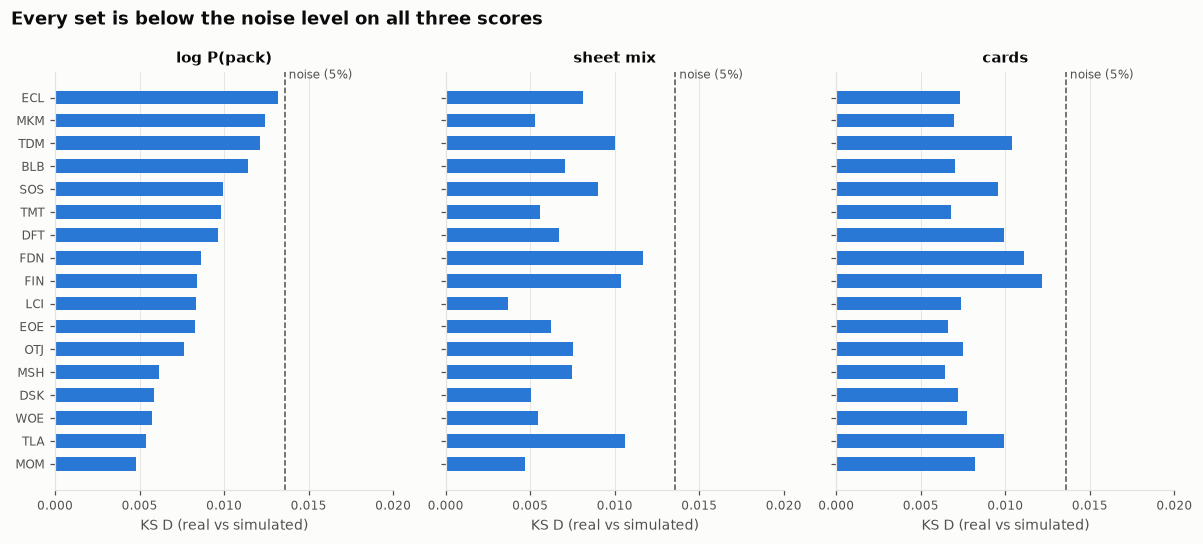

In [4]:
order = sorted(CODES, key=lambda c: R[c]["ks"]["log P(pack)"].statistic)
noise = crit(N_REAL, N_REAL)
fig, axes = plt.subplots(1, 3, figsize=(11, 5), sharey=True)
for ax, name in zip(axes, ["log P(pack)", "sheet mix", "cards"]):
    d = [R[c]["ks"][name].statistic for c in order]
    ax.barh(order, d, color=REAL, height=0.6)
    ax.axvline(noise, color=MUTED, ls="--", lw=1)
    ax.text(noise, len(order) - 0.3, " noise (5%)", color=MUTED, fontsize=8, va="bottom")
    ax.set_title(name); ax.set_xlabel("KS D (real vs simulated)"); ax.set_xlim(0, max(0.02, max(d) * 1.15))
    ax.set_xticks([0, 0.005, 0.01, 0.015, 0.02])
    ax.grid(axis="y", visible=False)
fig.suptitle("Every set is below the noise level on all three scores", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## 3. Score distributions

These are histograms of log P(pack) for real packs and held-out simulated packs. The curves should lie on top of each other.
Spikes come from the sheet-mix term, which takes only a handful of values.

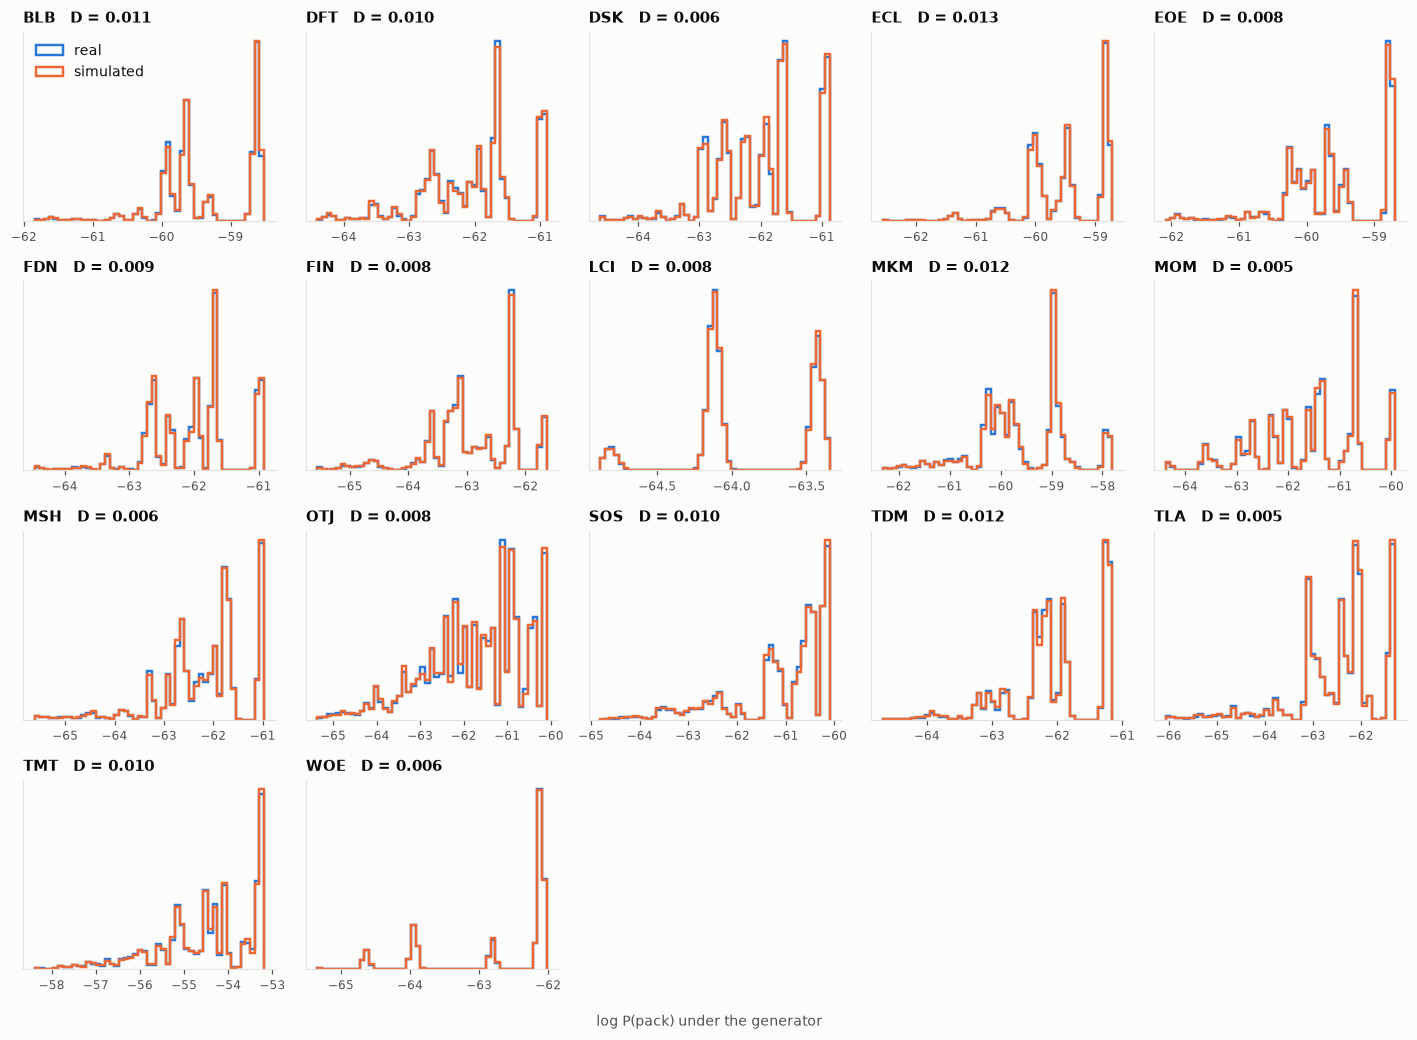

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(13, 9.5))
for ax, code in zip(axes.flat, CODES):
    r = R[code]
    a, b = r["score_real"][np.isfinite(r["score_real"])], r["score_sim"][np.isfinite(r["score_sim"])]
    bins = np.linspace(np.percentile(np.concatenate([a, b]), 0.5), np.percentile(np.concatenate([a, b]), 99.5), 50)
    ax.hist(a, bins, histtype="step", color=REAL, lw=1.6, density=True, label="real")
    ax.hist(b, bins, histtype="step", color=SIM, lw=1.6, density=True, label="simulated")
    ax.set_title(f"{code}   D = {r['ks']['log P(pack)'].statistic:.3f}", loc="left")
    ax.set_yticks([]); ax.grid(False)
for ax in axes.flat[len(CODES):]:
    ax.axis("off")
axes.flat[0].legend(loc="upper left")
fig.supxlabel("log P(pack) under the generator", color=MUTED, fontsize=9)
fig.tight_layout()

## 4. Cards per pack from each sheet

Each point is one sheet of one set, for example BLB commons or OTJ Breaking News rares. It is placed at its z-score:
(real mean − simulated mean) divided by its standard error. If the generator is right these follow a standard normal.
The curve shows that normal, scaled to the number of sheets.

set,sheet,real,sim,z
str,str,f64,f64,f64
"""MOM""","""DC""",0.45105,0.43665,2.898638
"""MOM""","""UB""",0.80305,0.8138,-2.731868
"""DFT""","""R""",1.13025,1.11535,2.465372
"""MOM""","""RB""",0.162,0.15325,2.401453
"""BLB""","""R""",1.0785,1.06675,2.113036
"""DFT""","""U""",3.985,3.99865,-2.093786
"""FDN""","""U""",3.9144,3.9287,-2.081899
"""MOM""","""M""",0.06775,0.07295,-2.033452
"""SOS""","""SPG""",0.0172,0.01985,-1.965387


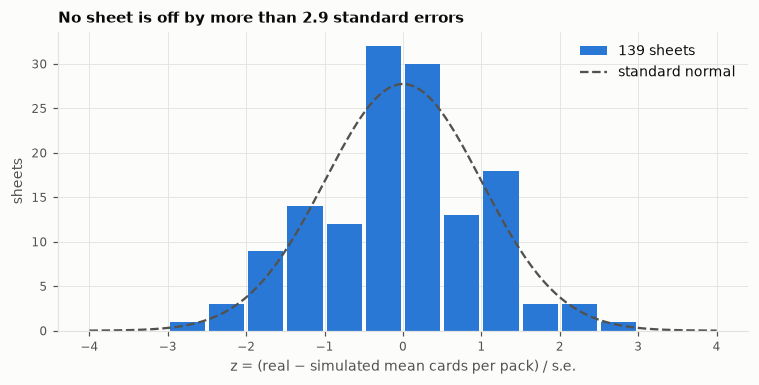

In [6]:
sheets = pl.concat([r["sheets"] for r in R.values()]).filter(pl.col("real") + pl.col("sim") > 0)
z = sheets["z"].to_numpy()
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.arange(-4, 4.25, 0.5)
ax.hist(z, bins, color=REAL, rwidth=0.9, label=f"{len(z)} sheets")
x = np.linspace(-4, 4, 200)
ax.plot(x, stats.norm.pdf(x) * len(z) * 0.5, color=MUTED, lw=1.5, ls="--", label="standard normal")
ax.set_xlabel("z = (real − simulated mean cards per pack) / s.e."); ax.set_ylabel("sheets")
ax.legend(); ax.set_title(f"No sheet is off by more than {np.abs(z).max():.1f} standard errors", loc="left")
fig.tight_layout()
sheets.sort(pl.col("z").abs(), descending=True).head(10)

## 5. Individual cards

### Card frequencies

Each dot is one card: copies per pack in real packs against simulated packs, on log axes. The dots should sit on the
diagonal. Spread around it is sampling noise, which is largest for rare cards (20,000 real packs).

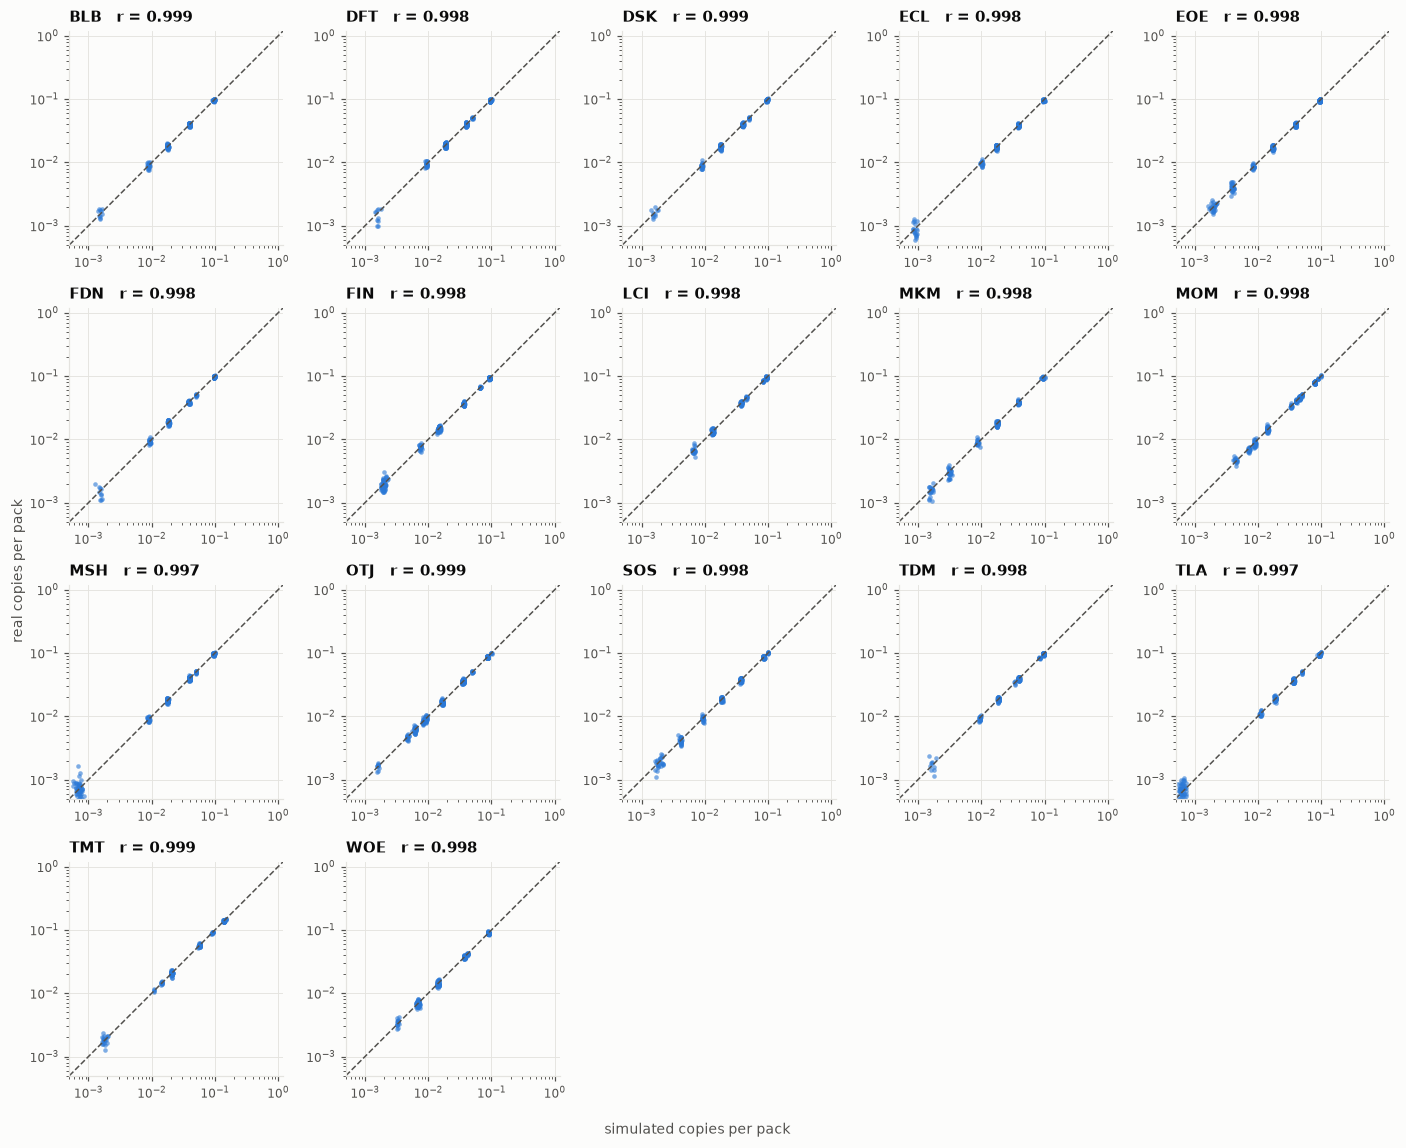

In [7]:
cards = pl.concat([r["card"] for r in R.values()])
fig, axes = plt.subplots(4, 5, figsize=(13, 10.5))
for ax, code in zip(axes.flat, CODES):
    d = cards.filter((pl.col("set") == code) & (pl.col("sim") > 0))
    ax.scatter(d["sim"], d["real"].clip(1e-5), s=9, color=REAL, alpha=0.6, linewidths=0)
    lo, hi = 5e-4, 1.2
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    r = np.corrcoef(np.log(d["sim"]), np.log(d["real"].clip(1e-5)))[0, 1]
    ax.set_title(f"{code}   r = {r:.3f}", loc="left")
for ax in axes.flat[len(CODES):]:
    ax.axis("off")
fig.supxlabel("simulated copies per pack", color=MUTED, fontsize=9)
fig.supylabel("real copies per pack", color=MUTED, fontsize=9)
fig.tight_layout()

### Chi-square calibration

For each sheet, a chi-square test asks whether its cards show up in the same proportions in real and simulated packs.
If the generator is right, the p-values are spread evenly between 0 and 1 (dashed line). A pile-up near 0 would mean
real per-card mismatches.

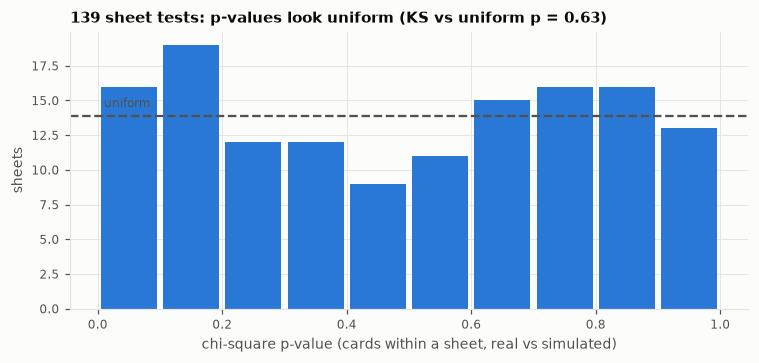

In [8]:
ps = np.array([p for r in R.values() for _, p in r["chi"]])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(ps, np.linspace(0, 1, 11), color=REAL, rwidth=0.9)
ax.axhline(len(ps) / 10, color=MUTED, ls="--", lw=1.5)
ax.text(0.01, len(ps) / 10 + 0.4, "uniform", color=MUTED, fontsize=8, va="bottom")
ax.set_xlabel("chi-square p-value (cards within a sheet, real vs simulated)"); ax.set_ylabel("sheets")
ax.set_title(f"{len(ps)} sheet tests: p-values look uniform (KS vs uniform p = {stats.kstest(ps, 'uniform').pvalue:.2f})", loc="left")
fig.tight_layout()

## 6. What the score can't see

Three checks fall outside the score:
- **Duplicates:** how often a pack holds two copies of a card.
- **Colour balance:** how often the commons cover all five colours (a gold card counts for each of its colours).
- **Same-colour pairing:** how often two commons of the same colour share a pack, relative to chance. 1 means
  independent; Arena's balancing keeps it well below 1.

Real packs are the large blue dots and simulated packs the small orange dots drawn on top, so where the
two agree you see an orange dot inside a blue ring. A grey line joins each set's pair.

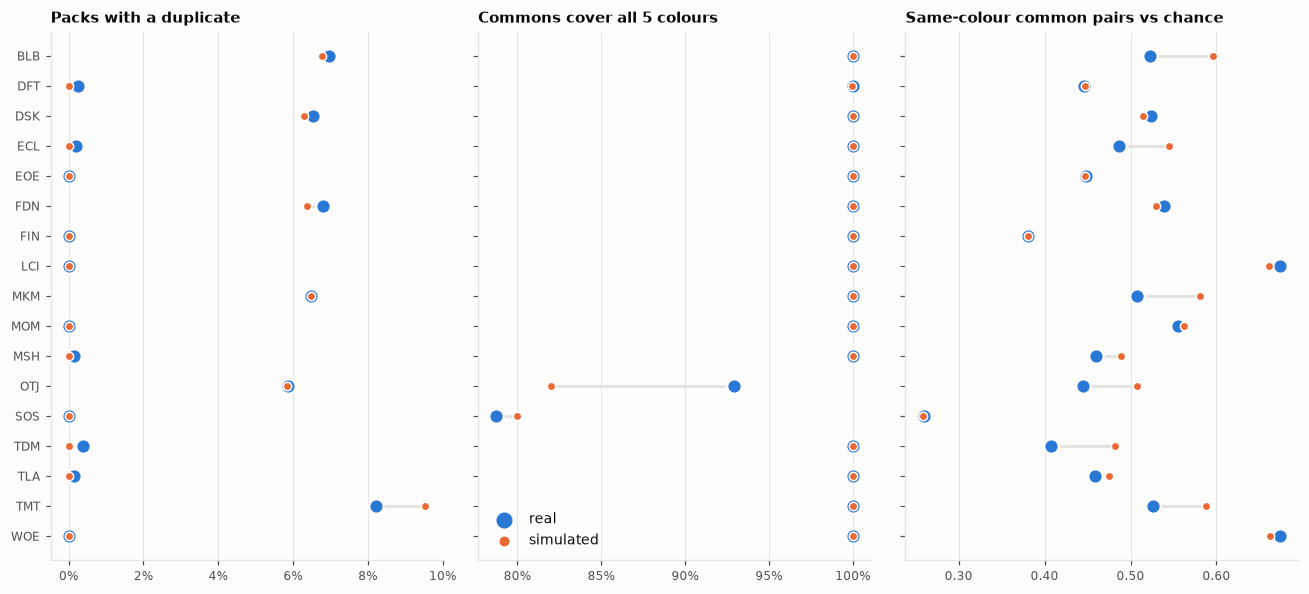

In [9]:
def dumbbell(ax, key, title, fmt):
    for i, c in enumerate(CODES):
        a, b = R[c][key]
        ax.plot([a, b], [i, i], color=GRID, lw=2, zorder=1)
        ax.scatter([a], [i], color=REAL, s=90, zorder=2, edgecolors="#fcfcfb", linewidths=1.5)
        ax.scatter([b], [i], color=SIM, s=30, zorder=3, edgecolors="#fcfcfb", linewidths=1)
    ax.set_yticks(range(len(CODES)), CODES); ax.invert_yaxis(); ax.set_title(title, loc="left")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(fmt)); ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 5.5), sharey=True)
pct = lambda x, _: f"{x:.0%}"
dumbbell(axes[0], "dup", "Packs with a duplicate", pct)
dumbbell(axes[1], "five", "Commons cover all 5 colours", pct)
dumbbell(axes[2], "pairs", "Same-colour common pairs vs chance", lambda x, _: f"{x:.2f}")
axes[1].scatter([], [], color=REAL, s=90, label="real"); axes[1].scatter([], [], color=SIM, s=30, label="simulated")
axes[1].legend(loc="lower left")
fig.tight_layout()

**What's still off.** Duplicates and colour coverage match within about a percentage point, with three exceptions:
- **OTJ colour coverage:** real packs cover all five colours more often than simulated ones.
- **TMT duplicates:** simulated packs have slightly too many.
- **Duplicates from DFT on:** real packs have a handful, 0.1–0.4%, where the generator makes none.

Same-colour pairing is right on average, but in some sets (TDM, MKM, TMT, OTJ, BLB) the simulated packs put two
same-colour commons together a bit more often than Arena does. Arena's exact balancing algorithm isn't published.
The generator's rules ("redraw until every colour shows / no more than two of a colour") reproduce its coverage and
per-card rates, but not every detail of its pairing. None of these differences shows up in the likelihood test above.

## 7. Documented vs Arena rates

The generator starts from Wizards' published rates. Where 17Lands rejected them, `tools/fit_rates.py` measured Arena's
actual rates on the *other* half of the drafts, and those are used instead. This table compares the documented and used
values for the rare slot and the two wildcards. For the second wildcard, the documented value is paper's foil slot.
Rows only appear where the two differ.

In [10]:
from collation import per_card
def mix(w, sizes):
    w = {s: x * sizes[s] for s, x in w.items()} if isinstance(w, per_card) else dict(w)
    g = {"DUAL": "R", "TC": "C", "TU": "U", "TR": "R", "TM": "M"}
    out = Counter()
    for s, x in w.items():
        out[g.get(s, s)] += x
    t = sum(out.values())
    return {k: v / t for k, v in out.items()}

rows = []
for code in CODES:
    spec = SETS[code]
    if "documented" not in spec:
        continue
    col = json.loads((SITE / "data" / f"{code}.json").read_text())["collation"]
    sizes = {s: len(v) for s, v in col["sheets"].items()}
    used_slots = [dict(sl["w"]) for sl in col["layouts"][0]["slots"]]
    rare_used = next(w for w in used_slots if set(w) == {"R", "M"})
    wilds_used = [w for w in used_slots if {"C", "U", "R", "M"} <= set(w)]
    for slot, doc, used in (("rare slot", spec["documented"]["rare"], rare_used),
                            ("wildcard", spec["documented"]["wild"], wilds_used[0]),
                            ("2nd wildcard", spec["documented"]["foil"], wilds_used[1])):
        d, u = mix(doc, sizes), mix(used, sizes)
        for k in sorted(set(d) | set(u), key=lambda k: ("CURM" + k).index(k)):
            if abs(d.get(k, 0) - u.get(k, 0)) >= 0.005:
                rows.append({"set": code, "slot": slot, "rarity/sheet": k,
                             "documented %": round(100 * d.get(k, 0), 1), "Arena (used) %": round(100 * u.get(k, 0), 1)})
with pl.Config(tbl_rows=200):
    display(pl.DataFrame(rows))

set,slot,rarity/sheet,documented %,Arena (used) %
str,str,str,f64,f64
"""BLB""","""wildcard""","""C""",20.0,16.6
"""BLB""","""wildcard""","""U""",64.5,66.6
"""BLB""","""wildcard""","""R""",13.3,14.3
"""BLB""","""2nd wildcard""","""C""",58.0,61.6
"""BLB""","""2nd wildcard""","""U""",32.0,30.0
"""BLB""","""2nd wildcard""","""R""",8.6,7.2
"""DFT""","""rare slot""","""R""",86.0,84.3
"""DFT""","""rare slot""","""M""",14.0,15.7
"""DFT""","""wildcard""","""C""",12.5,9.1


## 8. Other Arena differences found along the way

These aren't covered by the rate table. Each is cited in `tools/collation.py`.

- **Land slots:** Arena keeps the land slot only when it can hold a nonbasic. Its splits also differ from paper:
  - FIN: 67/33 dual/basic (paper 55/45)
  - LCI: 58/42 (paper 70/30)
  - TDM: 83/17 (paper 87/13)
  - TMT: 55/45 (paper 60/40)
- **Bonus sheets:**
  - WOE Enchanting Tales upgrade from uncommon to rare at about 1:4, not 1:3.
  - FIN Through the Ages follows the Arena drop-rates page (72/18.5/9.3), not the paper article.
- **Turtles (TMT):** they appear only in the second wildcard.
- **Colour balance** (no Wizards source):
  - Through DFT the commons always cover all five colours.
  - From TDM on, a pack never has more than two commons of one colour.
  - SOS has at most one common of each colour across its common slots.
  - OTJ balances only packs with 6 commons.
- **Duplicates** (no Wizards source):
  - The first wildcard never repeats a card already in the pack, but the second wildcard can.
  - From DFT on (except TMT), nothing in a pack repeats.